In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix

In [2]:
df=pd.read_csv("creditcard.csv")
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [4]:
print(df.duplicated().sum())

1081


In [5]:
df=df.drop_duplicates()
print(df.duplicated().sum())

0


In [7]:
print(df["Class"].value_counts())

Class
0    283253
1       473
Name: count, dtype: int64


In [8]:
print("Missing values in CLass : ",df["Class"].isna().sum())
df=df.dropna(subset=["Class"])

Missing values in CLass :  0


In [9]:
X=df.drop("Class",axis=1)
y=df['Class']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [10]:
print("training data : ",X_train.shape)
print("Testing Data : ",X_test.shape)

training data :  (226980, 30)
Testing Data :  (56746, 30)


In [11]:
rf=RandomForestClassifier(n_estimators=100,max_depth=10,class_weight="balanced",random_state=42)

In [12]:
rf.fit(X_train,y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10, random_state=42)

In [13]:
y_pred=rf.predict(X_test)

In [14]:
print("Accuracy : ",accuracy_score(y_test,y_pred))

Accuracy :  0.9994008388256441


In [15]:
print("Confusion Matrix",confusion_matrix(y_test,y_pred))

Confusion Matrix [[56642     9]
 [   25    70]]


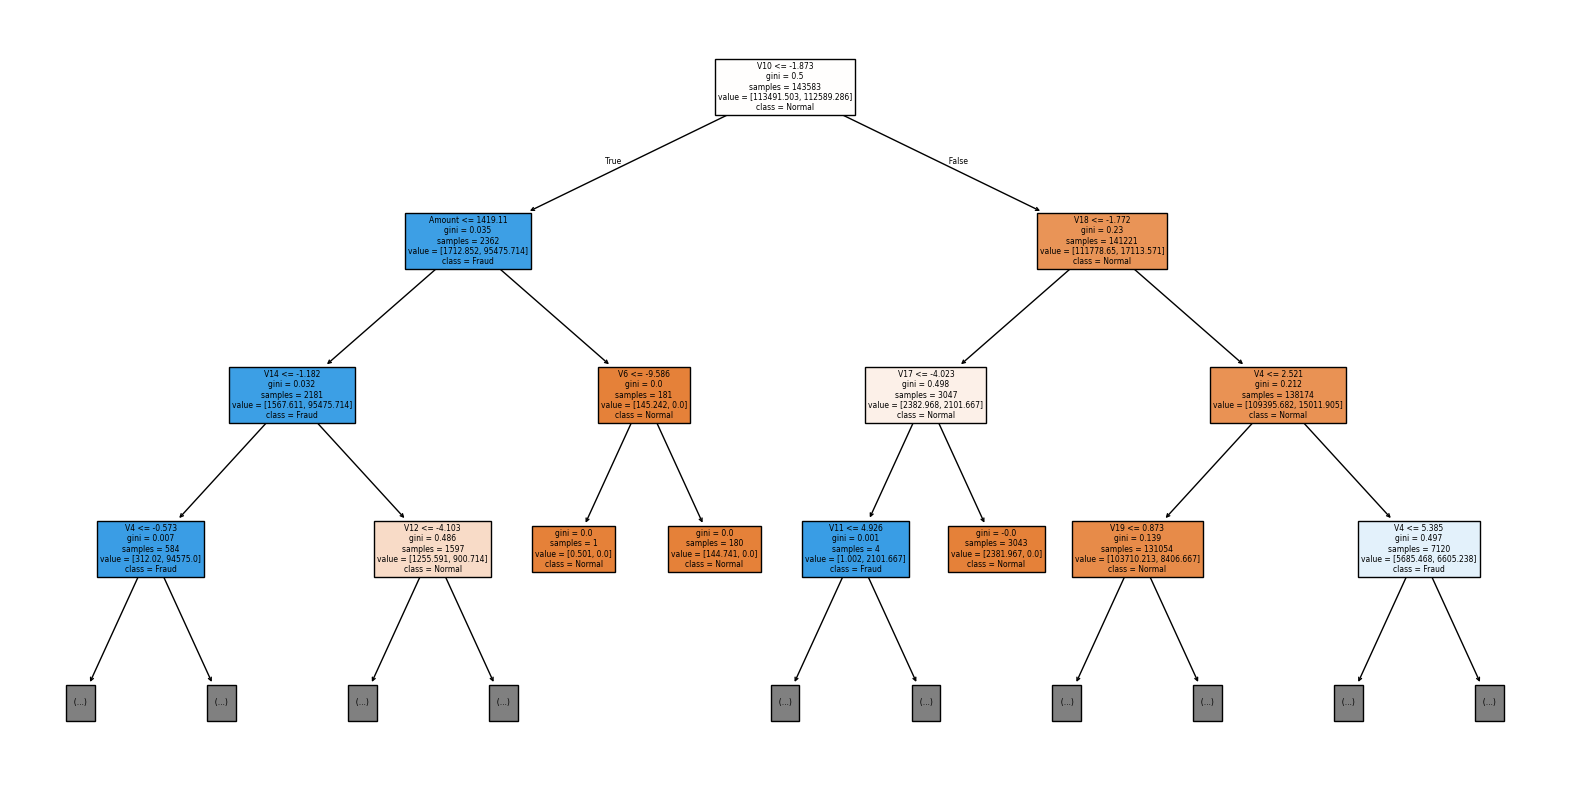

In [16]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    rf.estimators_[50],
    max_depth=3,
    feature_names=X.columns,
    class_names=["Normal", "Fraud"],
    filled=True
)

plt.show()

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
# Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
# Train SVM
svm = SVC(
    kernel="rbf",
    class_weight="balanced",
    random_state=42
)

svm.fit(X_train_scaled, y_train)

SVC(class_weight='balanced', random_state=42)

In [22]:
# Make Predictions
y_pred = svm.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9975681105276143

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.37      0.63      0.47        95

    accuracy                           1.00     56746
   macro avg       0.68      0.81      0.73     56746
weighted avg       1.00      1.00      1.00     56746



In [23]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[56548   103]
 [   35    60]]
